  [INFO] Detected nested layout: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/LA/LA


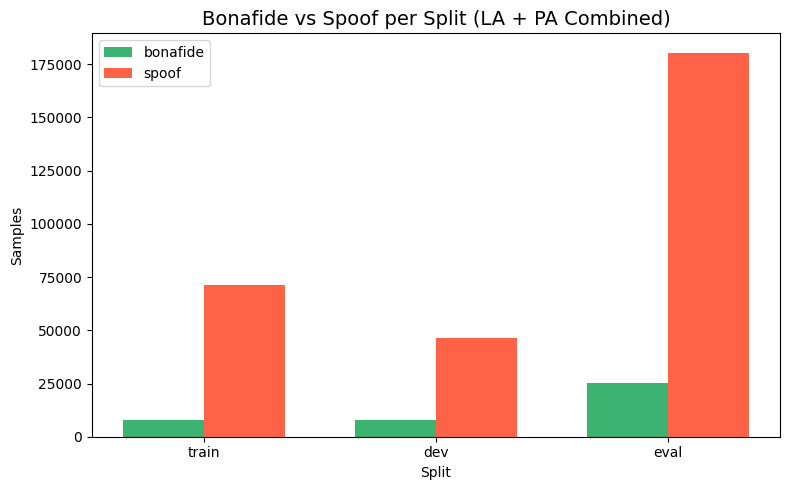


[1/6] Loading protocols …
  train:  25,380 samples
  dev  :  24,844 samples
  eval :  71,237 samples

[2/6] Printing statistics …

  DATASET STATISTICS

  Total samples : 121,461
  Unique speakers: 107
  Attack types  : 20 (['-', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19'])

  [TRAIN]
    bonafide :  2,580
    spoof    : 22,800  (ratio spoof/bonafide = 8.8x)

  [DEV]
    bonafide :  2,548
    spoof    : 22,296  (ratio spoof/bonafide = 8.8x)

  [EVAL]
    bonafide :  7,355
    spoof    : 63,882  (ratio spoof/bonafide = 8.7x)


[3/6] Plotting label distributions …


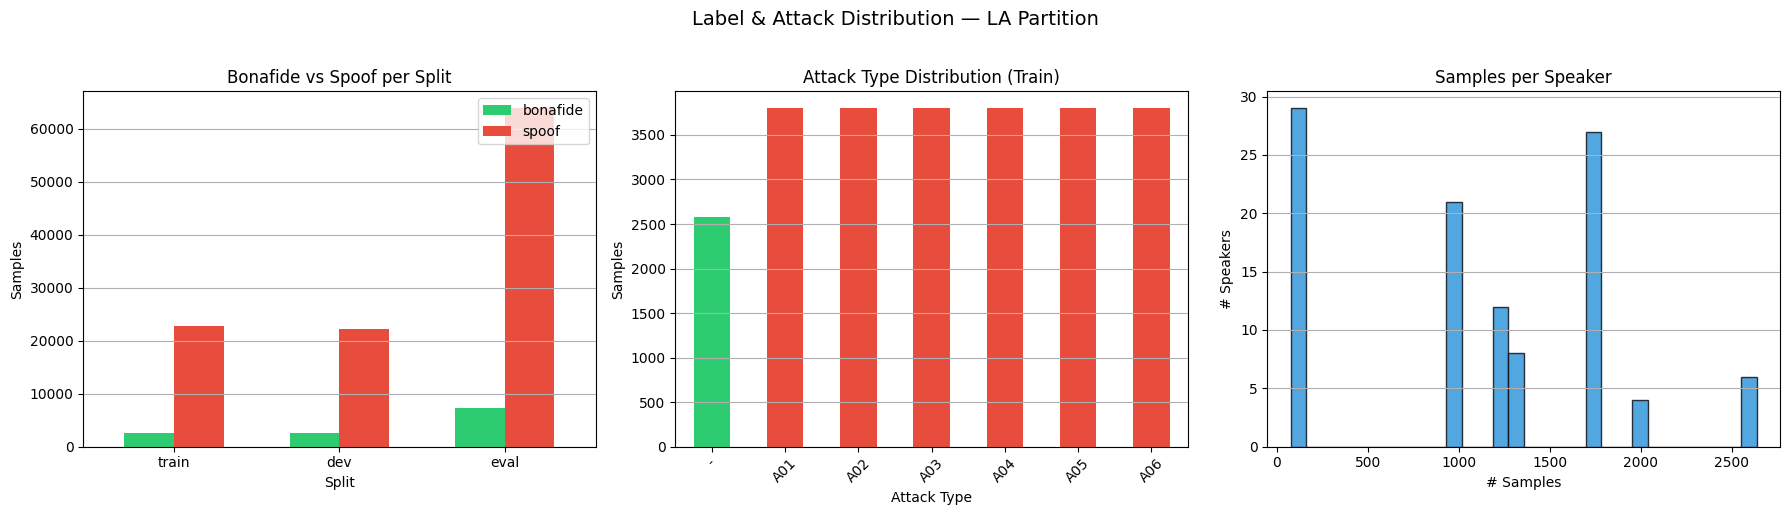

  Saved → plot1_label_distribution.png

[4/6] Extracting audio features (train, 200/class) …


  spoof (train): 100%|██████████| 200/200 [00:09<00:00, 20.88it/s]


       Feature table shape: (400, 50)
         duration                                                         \
            count    mean    std     min     25%     50%     75%     max   
label                                                                      
bonafide    200.0  3.3765  1.005  1.7448  2.6419  3.2355  3.9181  7.7836   
spoof       200.0  3.4268  1.385  1.1455  2.5124  3.1338  4.0516  9.1886   

         rms_mean          ... zcr_mean         centroid_mean             \
            count    mean  ...      75%     max         count       mean   
label                      ...                                             
bonafide    200.0  0.0767  ...   0.1377  0.2252         200.0  1806.2564   
spoof       200.0  0.0966  ...   0.1432  0.2129         200.0  1721.2836   

                                                                           
               std        min        25%        50%        75%        max  
label                                           

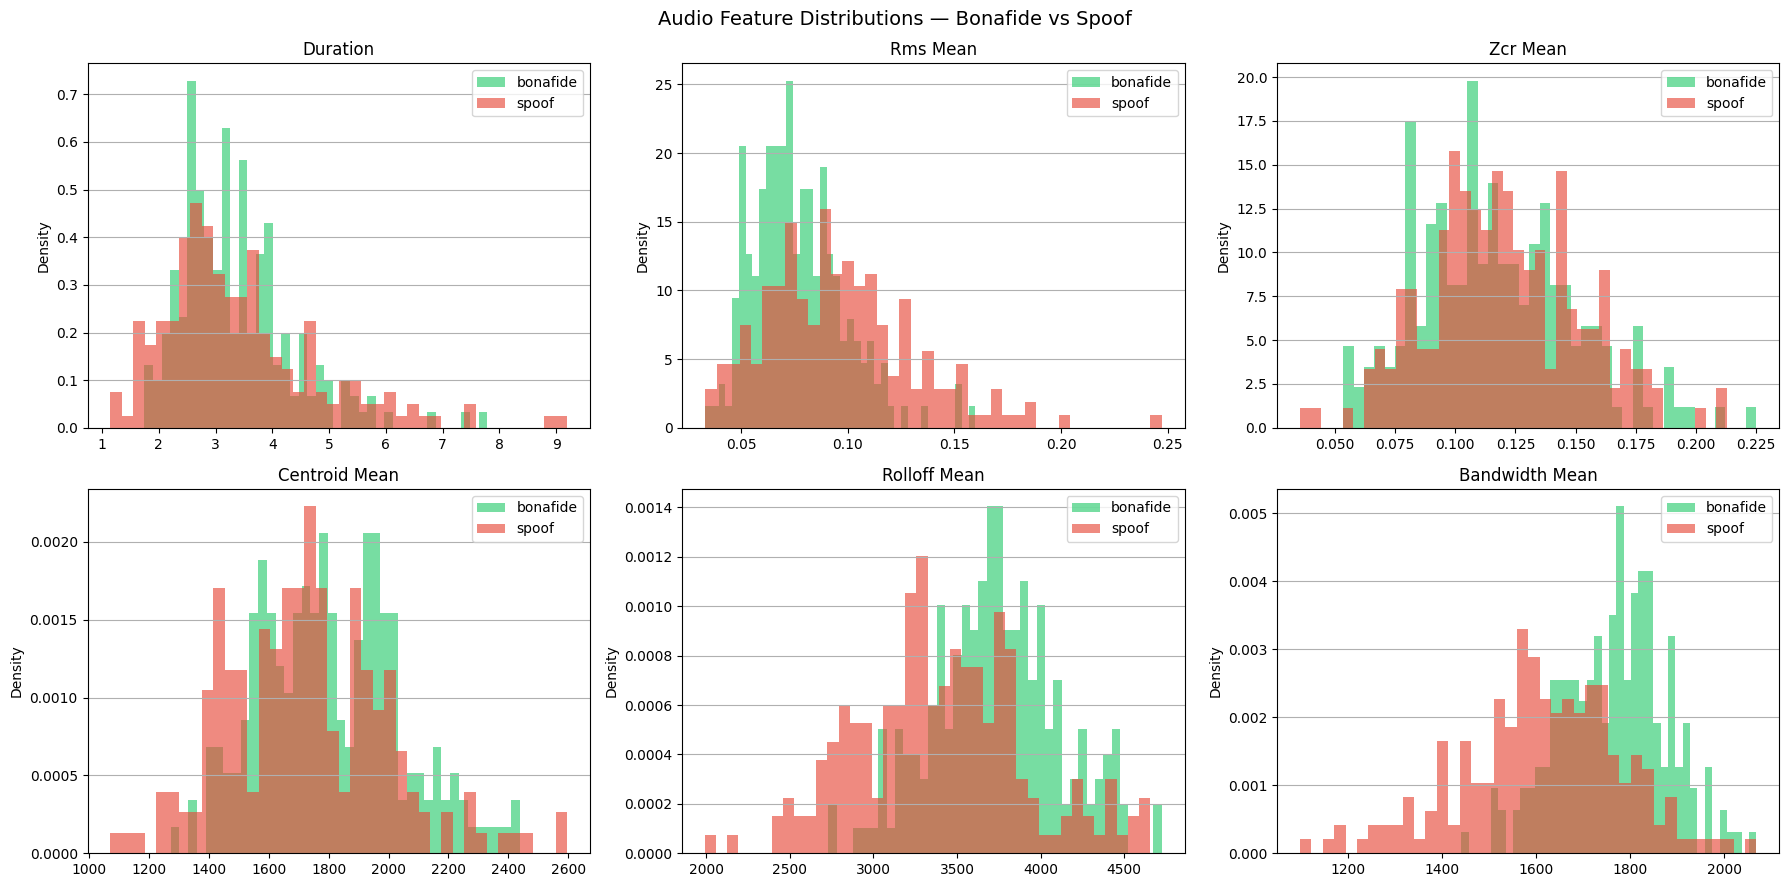

  Saved → plot2_audio_features.png


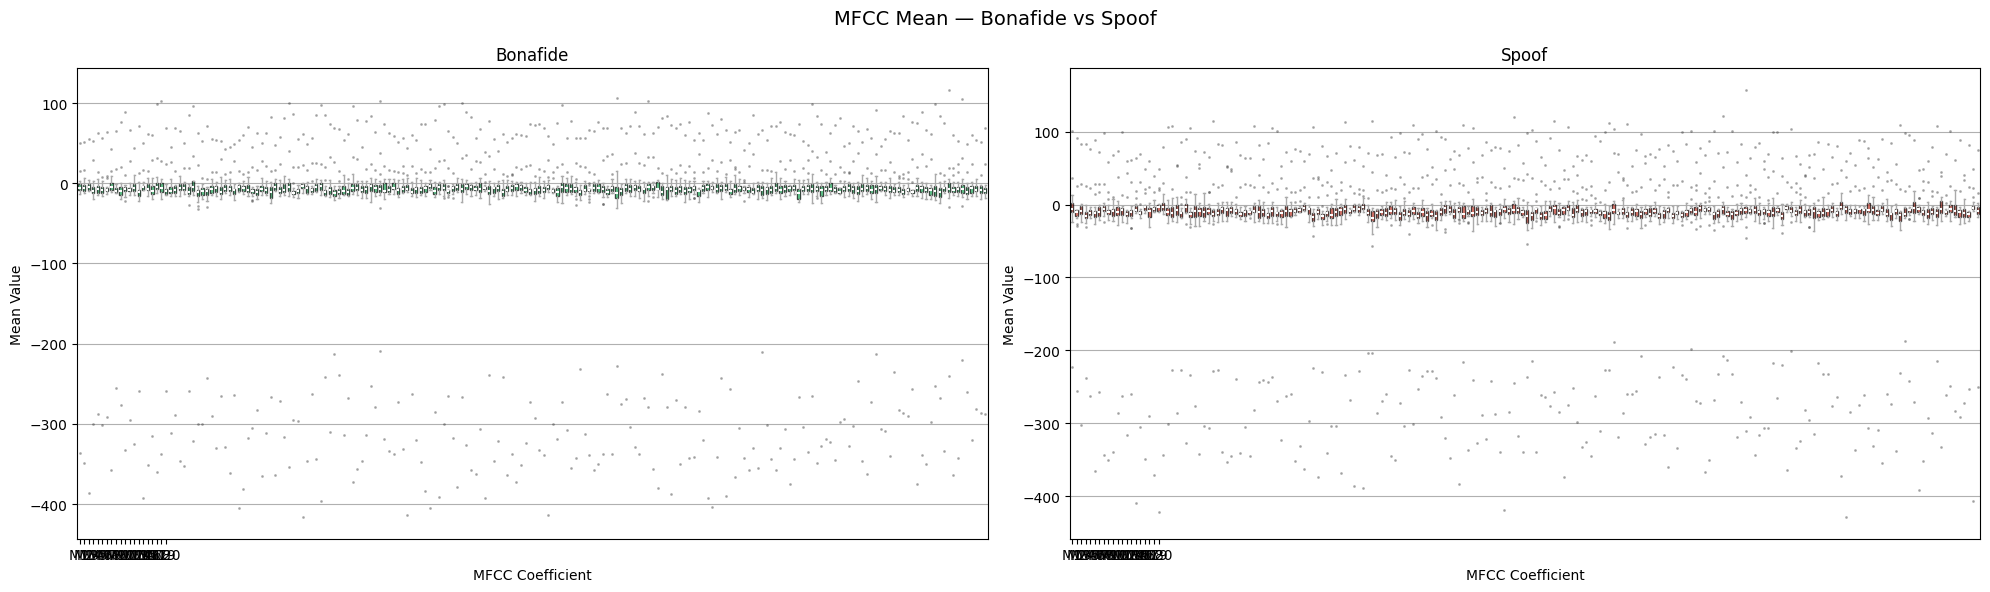

  Saved → plot3_mfcc_boxplot.png


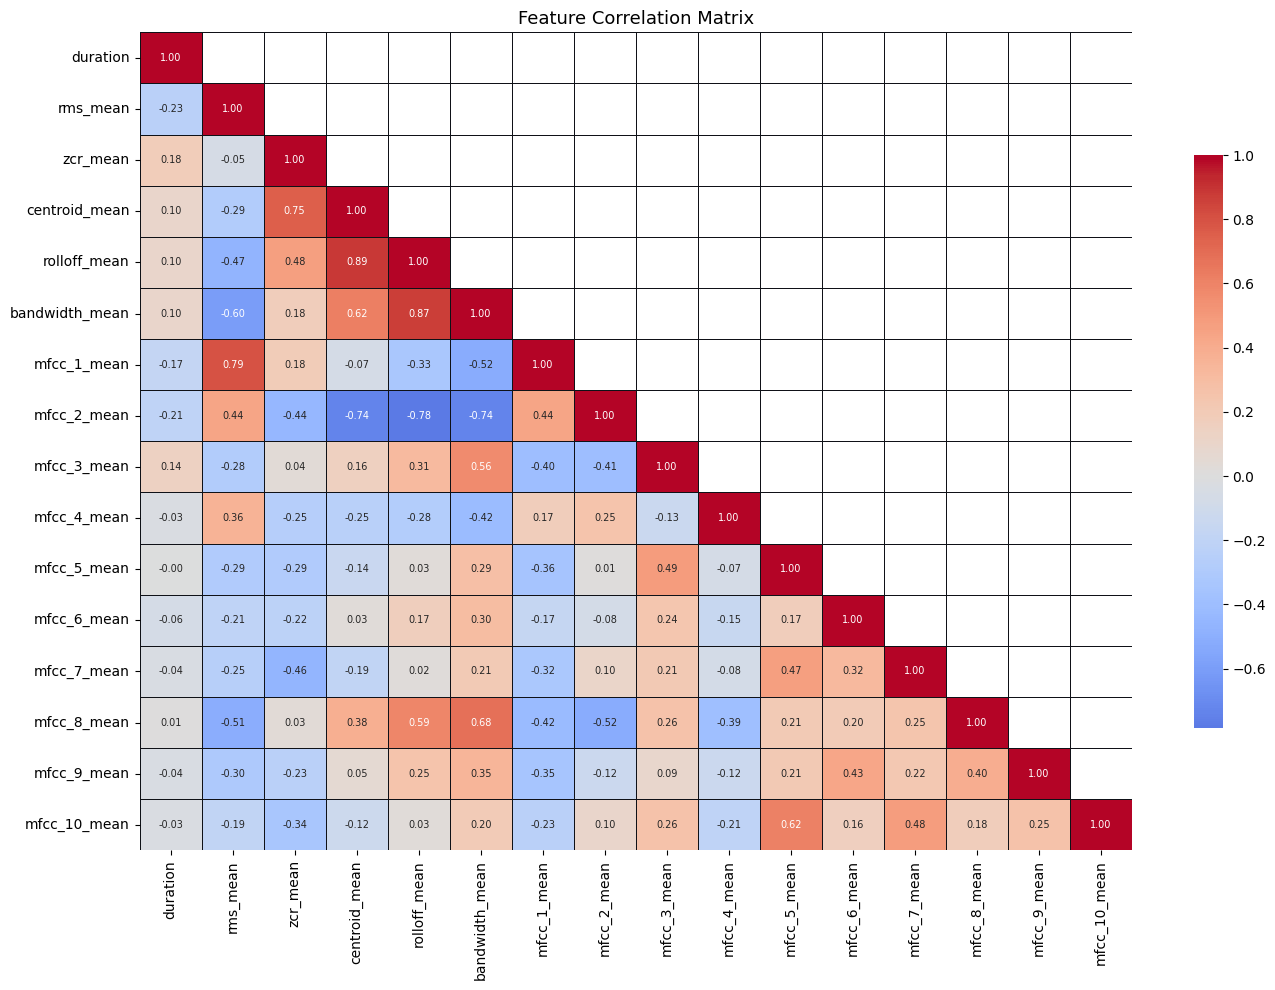

  Saved → plot4_correlation.png

[6/6] Plotting spectrograms …


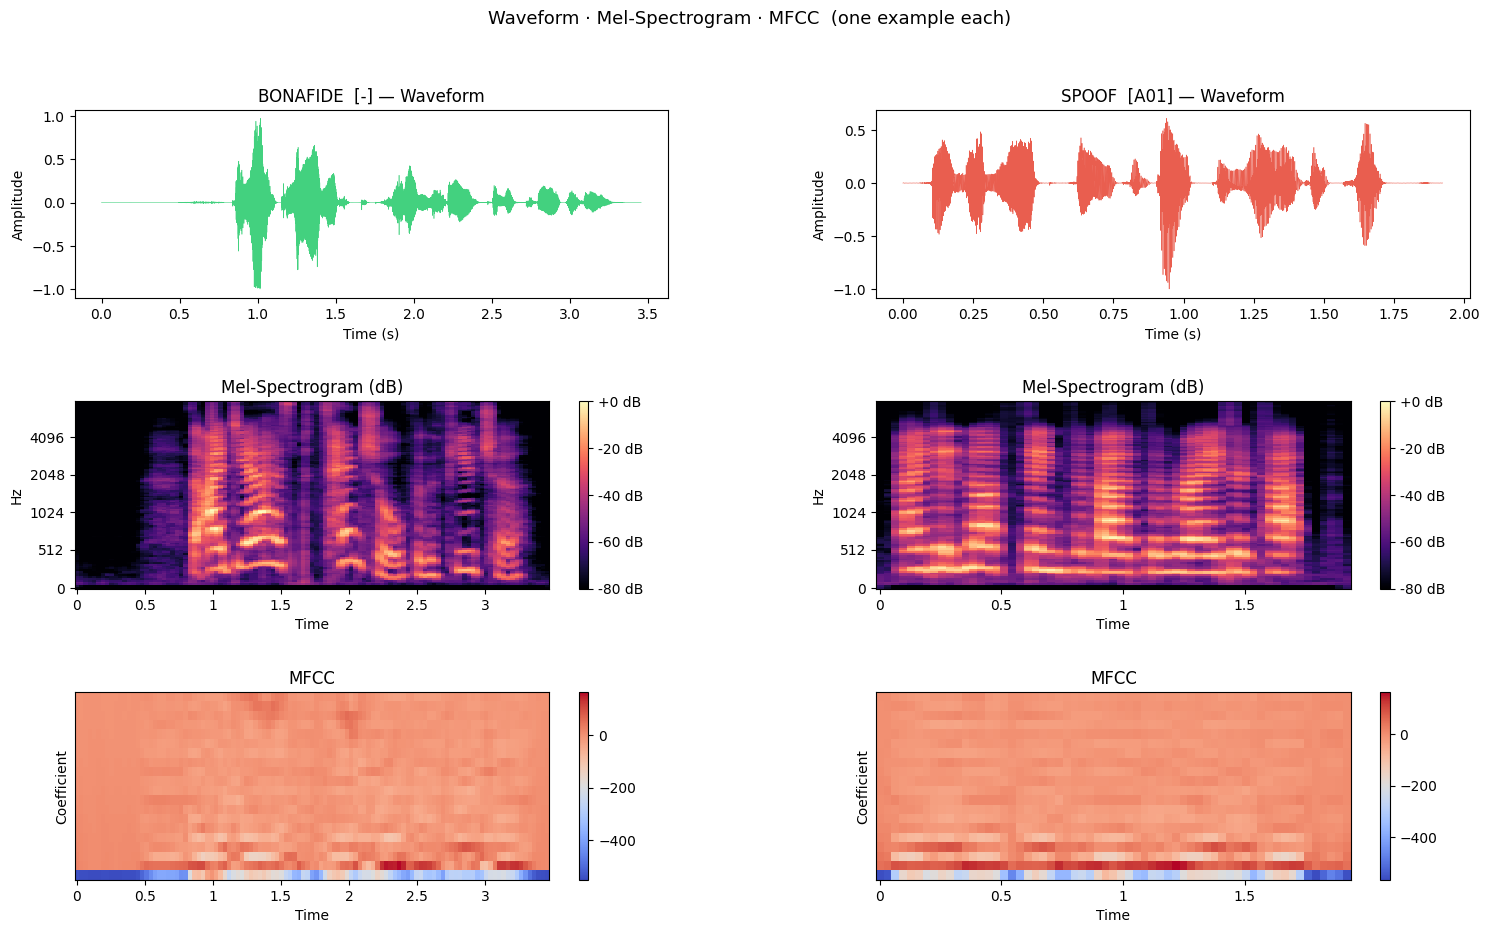

  Saved → plot5_spectrograms.png


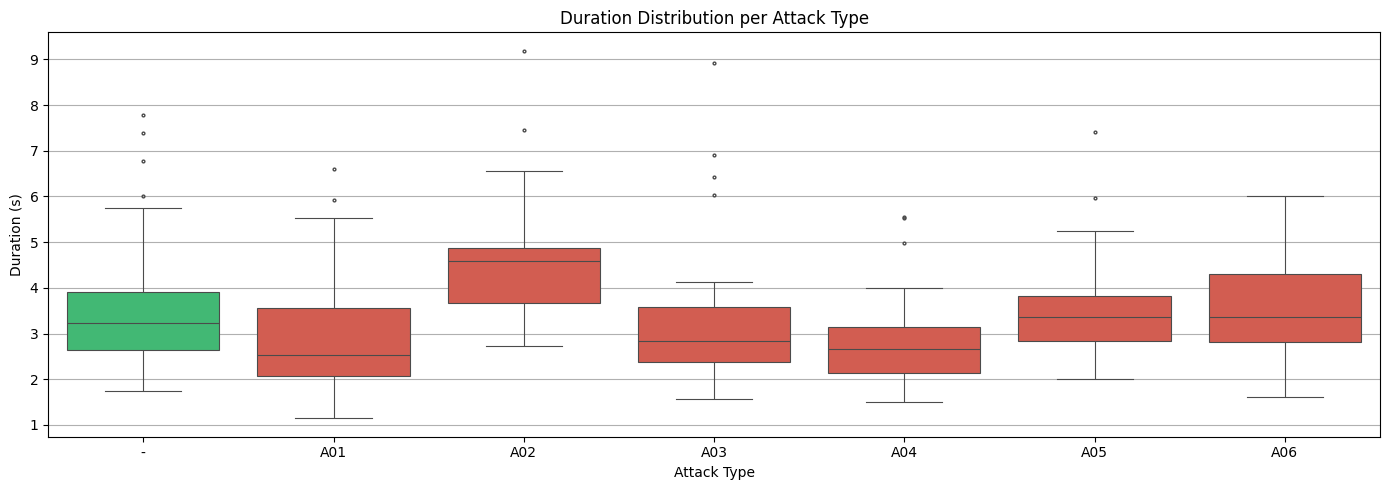

  Saved → plot6_duration_attack.png

✓ EDA complete — 6 plot files saved.


In [1]:
"""
ASVspoof 2019 Dataset - Exploratory Data Analysis
==================================================
Covers: dataset structure, label distributions, audio statistics,
        spectral features, and key visualizations.
"""

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import librosa
import librosa.display
from tqdm import tqdm

warnings.filterwarnings("ignore")

# ── Paths ─────────────────────────────────────────────────────────────────────
ROOT_DIR = Path("/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset")

# The dataset has a nested structure:  ROOT/LA/LA/...
# Auto-detect whether the inner LA folder exists, fall back to flat layout.
def _find_la_dir(root: Path) -> Path:
    nested = root / "LA" / "LA"
    flat   = root / "LA"
    if nested.exists():
        print(f"  [INFO] Detected nested layout: {nested}")
        return nested
    print(f"  [INFO] Detected flat layout: {flat}")
    return flat

LA_DIR = _find_la_dir(ROOT_DIR)
PA_DIR = ROOT_DIR / "PA"

PROTOCOL_LA = {
    "train": LA_DIR / "ASVspoof2019_LA_cm_protocols" / "ASVspoof2019.LA.cm.train.trn.txt",
    "dev":   LA_DIR / "ASVspoof2019_LA_cm_protocols" / "ASVspoof2019.LA.cm.dev.trl.txt",
    "eval":  LA_DIR / "ASVspoof2019_LA_cm_protocols" / "ASVspoof2019.LA.cm.eval.trl.txt",
}
AUDIO_LA = {
    "train": LA_DIR / "ASVspoof2019_LA_train" / "flac",
    "dev":   LA_DIR / "ASVspoof2019_LA_dev"   / "flac",
    "eval":  LA_DIR / "ASVspoof2019_LA_eval"  / "flac",
}

COLS = ["speaker_id", "file_id", "env_id", "attack_type", "label"]

# ── Styling ───────────────────────────────────────────────────────────────────
PALETTE = {"bonafide": "#2ecc71", "spoof": "#e74c3c"}
plt.rcParams.update({
    "figure.facecolor": "#0f1117",
    "axes.facecolor":   "#1a1d27",
    "axes.edgecolor":   "#3a3d4a",
    "axes.labelcolor":  "#e0e0e0",
    "xtick.color":      "#aaaaaa",
    "ytick.color":      "#aaaaaa",
    "text.color":       "#e0e0e0",
    "grid.color":       "#2a2d3a",
    "grid.alpha":       0.5,
    "font.family":      "monospace",
})

# ═══════════════════════════════════════════════════════════════════════════════
# 1. LOAD PROTOCOLS
# ═══════════════════════════════════════════════════════════════════════════════

def load_protocols():
    frames = {}
    for split, path in PROTOCOL_LA.items():
        if not path.exists():
            print(f"  [WARN] Protocol file not found: {path}")
            continue
        df = pd.read_csv(path, sep=" ", header=None, names=COLS)
        df["split"] = split
        frames[split] = df
        print(f"  {split:5s}: {len(df):>7,} samples")

    if not frames:
        print("\n  [ERROR] No protocol files loaded. Files found under LA_DIR:")
        for p in sorted(LA_DIR.rglob("*.txt"))[:20]:
            print(f"    {p}")
        raise FileNotFoundError(
            f"No protocol files found under {LA_DIR}.\n"
            "Ensure LA_DIR points to the folder containing ASVspoof2019_LA_cm_protocols/."
        )

    full = pd.concat(frames.values(), ignore_index=True)
    full["is_spoof"] = (full["label"] == "spoof").astype(int)
    return full, frames


# ═══════════════════════════════════════════════════════════════════════════════
# 2. STATISTICAL SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════

def print_stats(df: pd.DataFrame, frames: dict):
    print("\n" + "=" * 60)
    print("  DATASET STATISTICS")
    print("=" * 60)

    print(f"\n  Total samples : {len(df):,}")
    print(f"  Unique speakers: {df['speaker_id'].nunique()}")
    print(f"  Attack types  : {df['attack_type'].nunique()} "
          f"({sorted(df['attack_type'].unique())})")

    for split, sdf in frames.items():
        n_b = (sdf["label"] == "bonafide").sum()
        n_s = (sdf["label"] == "spoof").sum()
        ratio = n_s / n_b if n_b else float("inf")
        print(f"\n  [{split.upper()}]")
        print(f"    bonafide : {n_b:>6,}")
        print(f"    spoof    : {n_s:>6,}  (ratio spoof/bonafide = {ratio:.1f}x)")

    print()


# ═══════════════════════════════════════════════════════════════════════════════
# 3. PLOT 1 – Label & Attack Distribution
# ═══════════════════════════════════════════════════════════════════════════════

def plot_label_distribution(df: pd.DataFrame):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle("Label & Attack Distribution — LA Partition", fontsize=14, y=1.02)

    # 3a. Per-split bonafide vs spoof
    split_counts = (df.groupby(["split", "label"])
                      .size()
                      .unstack(fill_value=0)
                      .reindex(["train", "dev", "eval"]))
    split_counts.plot(kind="bar", ax=axes[0],
                      color=[PALETTE["bonafide"], PALETTE["spoof"]],
                      edgecolor="none", width=0.6)
    axes[0].set_title("Bonafide vs Spoof per Split")
    axes[0].set_xlabel("Split"); axes[0].set_ylabel("Samples")
    axes[0].tick_params(axis="x", rotation=0)
    axes[0].legend(loc="upper right")

    # 3b. Attack type counts (train only)
    train_df = df[df["split"] == "train"]
    atk_counts = (train_df["attack_type"]
                  .value_counts()
                  .sort_index())
    colors = [PALETTE["bonafide"] if idx == "-" else PALETTE["spoof"]
              for idx in atk_counts.index]
    atk_counts.plot(kind="bar", ax=axes[1], color=colors, edgecolor="none")
    axes[1].set_title("Attack Type Distribution (Train)")
    axes[1].set_xlabel("Attack Type"); axes[1].set_ylabel("Samples")
    axes[1].tick_params(axis="x", rotation=45)

    # 3c. Speaker sample count distribution
    spk_counts = df.groupby("speaker_id").size()
    axes[2].hist(spk_counts, bins=30,
                 color="#3498db", edgecolor="#0f1117", alpha=0.85)
    axes[2].set_title("Samples per Speaker")
    axes[2].set_xlabel("# Samples"); axes[2].set_ylabel("# Speakers")

    for ax in axes:
        ax.grid(axis="y")

    plt.tight_layout()
    plt.savefig("plot1_label_distribution.png", dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
    print("  Saved → plot1_label_distribution.png")

import matplotlib.pyplot as plt
import numpy as np

# Combined LA + PA counts
splits = ['train', 'dev', 'eval']
bonafide = [7980, 7948, 25445]
spoof = [71400, 46596, 180522]

x = np.arange(len(splits))
width = 0.35

plt.style.use('default')
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(x - width/2, bonafide, width, label='bonafide', color='mediumseagreen')
ax.bar(x + width/2, spoof, width, label='spoof', color='tomato')

ax.set_title('Bonafide vs Spoof per Split (LA + PA Combined)', fontsize=14)
ax.set_xlabel('Split')
ax.set_ylabel('Samples')
ax.set_xticks(x)
ax.set_xticklabels(splits)
ax.legend()

plt.tight_layout()
plt.show()
# ═══════════════════════════════════════════════════════════════════════════════
# 4. AUDIO FEATURE EXTRACTION (sample N files)
# ═══════════════════════════════════════════════════════════════════════════════

def extract_features(df: pd.DataFrame, split="train", n_per_class=200, sr=16_000):
    """Return a DataFrame with per-file audio statistics."""
    sdf = df[df["split"] == split].copy()
    audio_dir = AUDIO_LA[split]

    records = []
    for label in ["bonafide", "spoof"]:
        subset = sdf[sdf["label"] == label].sample(
            min(n_per_class, (sdf["label"] == label).sum()), random_state=42)

        for _, row in tqdm(subset.iterrows(),
                           total=len(subset),
                           desc=f"  {label} ({split})"):
            fpath = audio_dir / f"{row['file_id']}.flac"
            if not fpath.exists():
                continue
            y, _ = librosa.load(fpath, sr=sr, mono=True)
            duration = len(y) / sr

            mfcc     = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
            rms      = librosa.feature.rms(y=y)[0]
            zcr      = librosa.feature.zero_crossing_rate(y)[0]
            centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
            rolloff  = librosa.feature.spectral_rolloff(y=y, sr=sr)[0]
            bandwidth= librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]

            rec = {
                "file_id":    row["file_id"],
                "label":      label,
                "attack_type":row["attack_type"],
                "duration":   duration,
                "rms_mean":   rms.mean(),
                "rms_std":    rms.std(),
                "zcr_mean":   zcr.mean(),
                "centroid_mean": centroid.mean(),
                "rolloff_mean":  rolloff.mean(),
                "bandwidth_mean":bandwidth.mean(),
            }
            for i in range(20):
                rec[f"mfcc_{i+1}_mean"] = mfcc[i].mean()
                rec[f"mfcc_{i+1}_std"]  = mfcc[i].std()

            records.append(rec)

    return pd.DataFrame(records)


# ═══════════════════════════════════════════════════════════════════════════════
# 5. PLOT 2 – Audio Feature Comparison
# ═══════════════════════════════════════════════════════════════════════════════

def plot_audio_features(feat_df: pd.DataFrame):
    features = ["duration", "rms_mean", "zcr_mean",
                "centroid_mean", "rolloff_mean", "bandwidth_mean"]
    labels_order = ["bonafide", "spoof"]
    colors = [PALETTE[l] for l in labels_order]

    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    fig.suptitle("Audio Feature Distributions — Bonafide vs Spoof", fontsize=14)

    for ax, feat in zip(axes.flat, features):
        for label, color in zip(labels_order, colors):
            vals = feat_df[feat_df["label"] == label][feat].dropna()
            ax.hist(vals, bins=40, alpha=0.65, color=color,
                    label=label, edgecolor="none", density=True)
        ax.set_title(feat.replace("_", " ").title())
        ax.set_ylabel("Density")
        ax.legend()
        ax.grid(axis="y")

    plt.tight_layout()
    plt.savefig("plot2_audio_features.png", dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
    print("  Saved → plot2_audio_features.png")


# ═══════════════════════════════════════════════════════════════════════════════
# 6. PLOT 3 – MFCC Box-plots
# ═══════════════════════════════════════════════════════════════════════════════

def plot_mfcc_boxplot(feat_df: pd.DataFrame):
    mfcc_cols = [f"mfcc_{i}_mean" for i in range(1, 21)]

    fig, axes = plt.subplots(1, 2, figsize=(20, 6))
    fig.suptitle("MFCC Mean — Bonafide vs Spoof", fontsize=14)

    for ax, label in zip(axes, ["bonafide", "spoof"]):
        data = feat_df[feat_df["label"] == label][mfcc_cols].values
        ax.boxplot(data.T, patch_artist=True,
                   boxprops=dict(facecolor=PALETTE[label], alpha=0.7),
                   medianprops=dict(color="white", linewidth=1.5),
                   whiskerprops=dict(color="#aaaaaa"),
                   capprops=dict(color="#aaaaaa"),
                   flierprops=dict(marker="o", markersize=1,
                                   markerfacecolor="#aaaaaa", alpha=0.3))
        ax.set_title(label.title())
        ax.set_xticks(range(1, 21))
        ax.set_xticklabels([f"M{i}" for i in range(1, 21)])
        ax.set_xlabel("MFCC Coefficient")
        ax.set_ylabel("Mean Value")
        ax.grid(axis="y")

    plt.tight_layout()
    plt.savefig("plot3_mfcc_boxplot.png", dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
    print("  Saved → plot3_mfcc_boxplot.png")


# ═══════════════════════════════════════════════════════════════════════════════
# 7. PLOT 4 – Correlation Heatmap
# ═══════════════════════════════════════════════════════════════════════════════

def plot_correlation(feat_df: pd.DataFrame):
    num_cols = (["duration", "rms_mean", "zcr_mean",
                 "centroid_mean", "rolloff_mean", "bandwidth_mean"]
                + [f"mfcc_{i}_mean" for i in range(1, 11)])

    corr = feat_df[num_cols].corr()

    fig, ax = plt.subplots(figsize=(14, 10))
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, ax=ax, cmap="coolwarm", center=0,
                linewidths=0.4, linecolor="#0f1117",
                annot=True, fmt=".2f", annot_kws={"size": 7},
                cbar_kws={"shrink": 0.7})
    ax.set_title("Feature Correlation Matrix", fontsize=13)
    plt.tight_layout()
    plt.savefig("plot4_correlation.png", dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
    print("  Saved → plot4_correlation.png")


# ═══════════════════════════════════════════════════════════════════════════════
# 8. PLOT 5 – Spectrogram & MFCC for one bonafide + one spoof file
# ═══════════════════════════════════════════════════════════════════════════════

def plot_spectrograms(df: pd.DataFrame, split="train", sr=16_000):
    audio_dir = AUDIO_LA[split]
    sdf = df[df["split"] == split]

    samples = {}
    for label in ["bonafide", "spoof"]:
        row = sdf[sdf["label"] == label].iloc[0]
        fpath = audio_dir / f"{row['file_id']}.flac"
        if fpath.exists():
            samples[label] = (fpath, row["attack_type"])

    if not samples:
        print("[WARN] No audio files found for spectrogram plot.")
        return

    fig = plt.figure(figsize=(18, 10))
    fig.suptitle("Waveform · Mel-Spectrogram · MFCC  (one example each)",
                 fontsize=13)
    gs = gridspec.GridSpec(3, 2, hspace=0.55, wspace=0.35)

    for col, (label, (fpath, atk)) in enumerate(samples.items()):
        y, _ = librosa.load(fpath, sr=sr, mono=True)
        times = np.linspace(0, len(y) / sr, len(y))
        mel   = librosa.power_to_db(
                    librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128), ref=np.max)
        mfcc  = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)

        title_prefix = f"{label.upper()}  [{atk}]"
        color = PALETTE[label]

        # waveform
        ax0 = fig.add_subplot(gs[0, col])
        ax0.plot(times, y, color=color, lw=0.4, alpha=0.9)
        ax0.set_title(title_prefix + " — Waveform")
        ax0.set_xlabel("Time (s)"); ax0.set_ylabel("Amplitude")

        # mel spectrogram
        ax1 = fig.add_subplot(gs[1, col])
        img = librosa.display.specshow(mel, sr=sr, x_axis="time",
                                       y_axis="mel", ax=ax1, cmap="magma")
        ax1.set_title("Mel-Spectrogram (dB)")
        fig.colorbar(img, ax=ax1, format="%+2.0f dB")

        # mfcc
        ax2 = fig.add_subplot(gs[2, col])
        img2 = librosa.display.specshow(mfcc, sr=sr, x_axis="time",
                                        ax=ax2, cmap="coolwarm")
        ax2.set_title("MFCC")
        ax2.set_ylabel("Coefficient")
        fig.colorbar(img2, ax=ax2)

    plt.savefig("plot5_spectrograms.png", dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
    print("  Saved → plot5_spectrograms.png")


# ═══════════════════════════════════════════════════════════════════════════════
# 9. PLOT 6 – Duration Distribution per Attack Type
# ═══════════════════════════════════════════════════════════════════════════════

def plot_duration_by_attack(feat_df: pd.DataFrame):
    order = sorted(feat_df["attack_type"].unique())
    palette = {a: PALETTE["bonafide"] if a == "-" else PALETTE["spoof"]
               for a in order}

    fig, ax = plt.subplots(figsize=(14, 5))
    sns.boxplot(data=feat_df, x="attack_type", y="duration",
                order=order, palette=palette, ax=ax,
                linewidth=0.8, fliersize=2)
    ax.set_title("Duration Distribution per Attack Type")
    ax.set_xlabel("Attack Type"); ax.set_ylabel("Duration (s)")
    ax.grid(axis="y")
    plt.tight_layout()
    plt.savefig("plot6_duration_attack.png", dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
    print("  Saved → plot6_duration_attack.png")


# ═══════════════════════════════════════════════════════════════════════════════
# MAIN
# ═══════════════════════════════════════════════════════════════════════════════

def main():
    print("\n[1/6] Loading protocols …")
    df, frames = load_protocols()

    print("\n[2/6] Printing statistics …")
    print_stats(df, frames)

    print("\n[3/6] Plotting label distributions …")
    plot_label_distribution(df)

    print("\n[4/6] Extracting audio features (train, 200/class) …")
    feat_df = extract_features(df, split="train", n_per_class=200)
    print(f"       Feature table shape: {feat_df.shape}")
    print(feat_df[["label", "duration", "rms_mean", "zcr_mean",
                   "centroid_mean"]].groupby("label").describe().round(4))

    print("\n[5/6] Plotting audio feature distributions …")
    plot_audio_features(feat_df)
    plot_mfcc_boxplot(feat_df)
    plot_correlation(feat_df)

    print("\n[6/6] Plotting spectrograms …")
    plot_spectrograms(df, split="train")
    plot_duration_by_attack(feat_df)

    print("\n✓ EDA complete — 6 plot files saved.")


if __name__ == "__main__":
    main()